# Meta-learners, leave one out

Combines the expert scores of one pool (the **base**) into one score per image, evaluated leave-one-out: one fold per expert,
whose generators are held out. The learner is fitted on `meta_train` of the other generators (without the held-out expert's
column) and evaluated on the held-out generators, the unseen test. See `meta/loo.py`, learners in `meta/learners/`.

Run the expert notebooks (training + scoring) of the chosen base first.

`EVAL_POOL = "meta_val"` while developing. `"test"` gives the final numbers: run it once, after every choice is frozen.


In [1]:
import sys
sys.path.insert(0, "..")  # repo root, so `clip`, `common`, `data`, `meta` and `resnet` are importable

from meta.learners import LEARNERS
from meta.loo import BASES, run_loo
from meta.run import load_results, plot_summary, run_all, summary

EVAL_POOL = "meta_val"  # "test" only for the final numbers
BASE = "resnet50"  # feature base: one of BASES ("clip", "resnet18", "resnet50")
LEARNER = "mean"  # meta-learner: one of LEARNERS
MERGE_SIBLINGS = True  # hold SD and wukong out together (6 folds) instead of separately (7 folds)

print("bases:", list(BASES), "| learners:", list(LEARNERS))


bases: ['clip', 'resnet18', 'resnet50'] | learners: ['best_expert', 'mean', 'avg', 'max', 'sorted_lr', 'sorted-lr', 'sorted_score_lr', 'stacking_lr', 'stacking-lr', 'lr', 'shuffled_mlp', 'shuffled-mlp', 'mlp', 'deep_sets', 'deep-sets', 'gating', 'gating_network', 'pu_stacking_lr', 'pu_mlp', 'pu_deep_sets', 'pu_gating']


## One learner on one pool

In [2]:
table = run_loo(LEARNERS[LEARNER](), BASE, MERGE_SIBLINGS, EVAL_POOL)
print(f"{LEARNER} on {BASE}")
table.round(4)


mean on resnet50


,generators,n_train,n_val,n_eval,auc,ap,acc,seen_auc,expert_mean_auc,expert_best_auc,gap
held out,,,,,,,,,,,
ADM,ADM,28000.0,14000.0,2000.0,0.9153,0.9116,0.7680,0.9877,0.7732,0.8896,0.0724
BigGAN,BigGAN,28000.0,14000.0,2000.0,0.9076,0.8923,0.7360,0.9872,0.7412,0.9670,0.0796
glide,glide,28000.0,14000.0,2000.0,0.9930,0.9927,0.9535,0.9851,0.9019,0.9938,-0.0079
Midjourney,Midjourney,28000.0,14000.0,2000.0,0.9488,0.9482,0.8545,0.9900,0.8008,0.9449,0.0412
VQDM,VQDM,28000.0,14000.0,2000.0,0.9139,0.8987,0.7510,0.9882,0.7540,0.9505,0.0743
SD+wukong,"stable_diffusion_v_1_4, stable_diffusion_v_1_5...",20000.0,10000.0,6000.0,0.9118,0.8866,0.7793,0.9871,0.7541,0.9233,0.0753
mean,NaN,NaN,NaN,NaN,0.9318,0.9217,0.8071,0.9875,0.7875,0.9449,0.0558


## All learners on all pools

Every learner on every pool, 3 seeds for the networks, saved to `results/` in the dataset folder (about an hour).
Skip the next cell if `load_results` already finds them.


In [3]:
# run_all(eval_pool=EVAL_POOL)
results = load_results(EVAL_POOL)
results.shape


(1558, 17)

### Unseen AUROC

`best_expert` is the RQ1 baseline. `pu_*` are trained with each image's own expert hidden (pseudo-unseen).


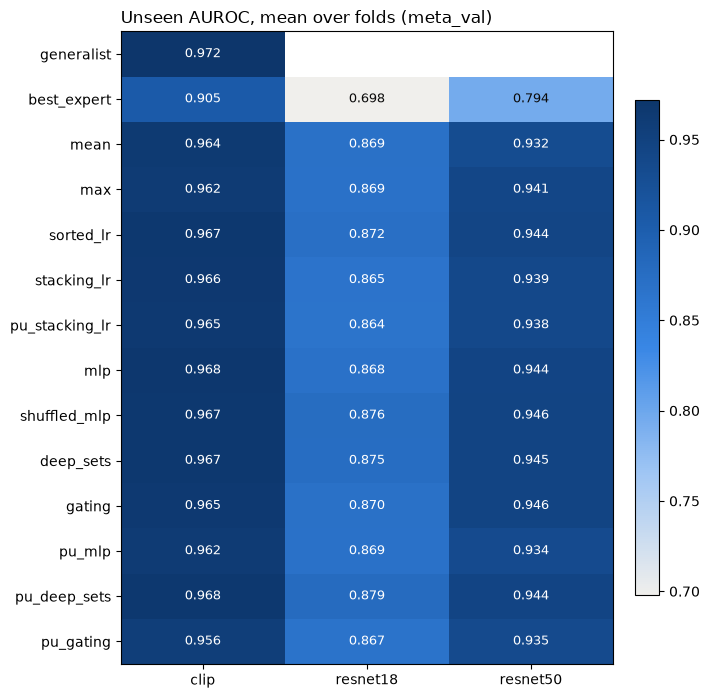

In [4]:
plot_summary(summary(results, "auc", MERGE_SIBLINGS), f"Unseen AUROC, mean over folds ({EVAL_POOL})")


### Seen minus unseen AUROC

On `meta_val` the seen images were used for early stopping, so this gap is only final on `test`.


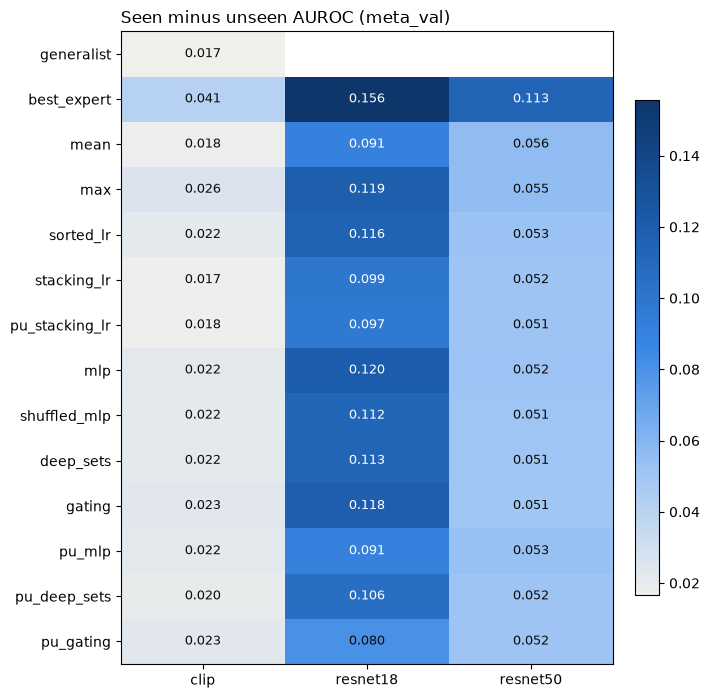

In [5]:
plot_summary(summary(results, "gap", MERGE_SIBLINGS), f"Seen minus unseen AUROC ({EVAL_POOL})")


### Accuracy at the threshold chosen on seen validation images


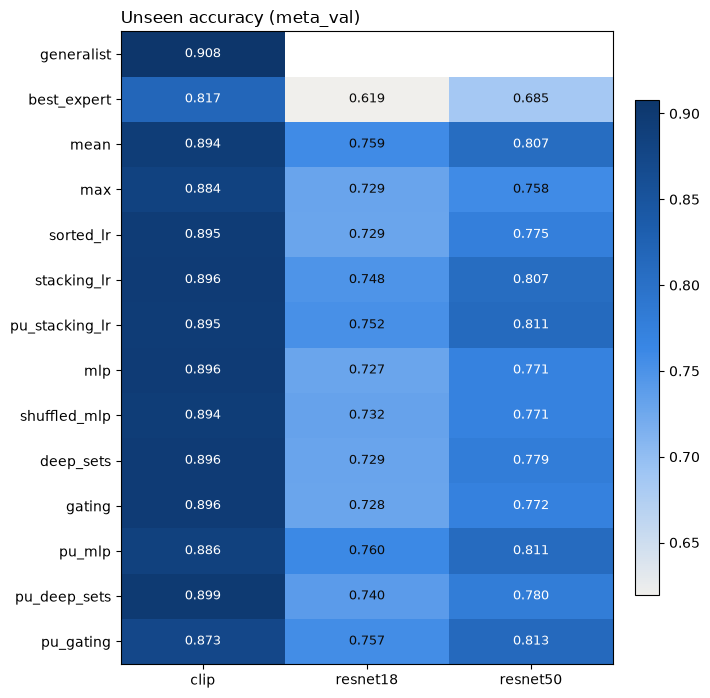

In [6]:
plot_summary(summary(results, "acc", MERGE_SIBLINGS), f"Unseen accuracy ({EVAL_POOL})")


## Are the differences real? (paired bootstrap)

Redraws the held-out images 1000 times and recomputes each comparison on the same redraws (`meta/bootstrap.py`).
`difference` is the first minus the second in mean unseen AUROC; `clear` means the 95% interval `low`-`high`
excludes 0. The comparisons are fixed in advance in `COMPARISONS`. Only image sampling is covered: the experts
were trained once.

In [7]:
from meta.bootstrap import run_bootstrap

bootstrap = run_bootstrap(eval_pool=EVAL_POOL, merge_siblings=MERGE_SIBLINGS)
bootstrap.round(4)

,question,comparison,difference,low,high,first_better_share,clear
0,RQ1,mean (clip) vs best_expert (clip),0.0590,0.0551,0.0628,1.000,True
1,RQ1,mlp (clip) vs best_expert (clip),0.0632,0.0591,0.0674,1.000,True
2,RQ1,mean (resnet18) vs best_expert (resnet18),0.1716,0.1647,0.1785,1.000,True
3,RQ1,mlp (resnet18) vs best_expert (resnet18),0.1703,0.1627,0.1779,1.000,True
4,RQ1,mean (resnet50) vs best_expert (resnet50),0.1376,0.1319,0.1434,1.000,True
5,RQ1,mlp (resnet50) vs best_expert (resnet50),0.1502,0.1435,0.1566,1.000,True
6,RQ1,generalist (clip) vs mean (clip),0.0083,0.0069,0.0096,1.000,True
7,RQ1,generalist (clip) vs sorted_lr (clip),0.0047,0.0031,0.0062,1.000,True
8,RQ1,generalist (clip) vs mlp (clip),0.0041,0.0026,0.0055,1.000,True
9,RQ1,generalist (clip) vs deep_sets (clip),0.0048,0.0033,0.0062,1.000,True
